# Uber Ride-Booking Analytics
### Exploratory Data Analysis, Operational Insights & OLS Regression

**Individual Python implementation** · Bucharest University of Economic Studies (ASE) · 2026

---

## Project context

This repository presents the Python component of a broader university software-packages assignment. The overall assignment was completed collaboratively; **the Python notebook in this repository was independently developed by Alexandru Măroiu**.

The analysis uses a 2024 Uber ride-booking dataset to explore booking outcomes, vehicle demand, revenue, customer ratings and operational patterns. It also estimates an ordinary least squares (OLS) model for completed rides.

**Scope:** Python only. SAS and SAS Enterprise Guide components of the broader assignment are not included.

## Questions explored

1. How are bookings distributed across vehicle categories and booking outcomes?
2. Which vehicle categories generate the highest booking volume and recorded booking value?
3. When does booking activity peak during the day?
4. What does the dataset reveal about ride distance, booking value and customer/driver ratings?
5. How are selected ride characteristics associated with booking value among completed rides?

## Dataset at a glance

The supplied CSV contains **150,000 booking records and 21 variables**. The records cover 2024 and include trip, booking, location, payment, operational-time and rating information.

The notebook is organized as a reproducible workflow: import → inspect → transform → assess missingness → aggregate → visualize → estimate an OLS model.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from IPython.display import display

pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda value: f"{value:,.2f}")

# Resolve the CSV path whether the notebook is launched from the project root
# or from the notebooks/ directory.
possible_paths = [
    Path.cwd() / "data" / "uber_data.csv",
    Path.cwd().parent / "data" / "uber_data.csv",
]
DATA_PATH = next((path for path in possible_paths if path.exists()), None)

if DATA_PATH is None:
    raise FileNotFoundError(
        "Could not find data/uber_data.csv. Run the notebook from the project "
        "root or keep the expected repository structure."
    )

df = pd.read_csv(DATA_PATH)
print(f"Loaded dataset: {df.shape[0]:,} rows × {df.shape[1]} columns")
print(f"Dataset path: {DATA_PATH}")

Loaded dataset: 150,000 rows × 21 columns
Dataset path: /mnt/data/uber-ride-booking-analytics/data/uber_data.csv


## 1. Initial data inspection

The initial inspection checks the dataset dimensions, variable names, data types, first observations and descriptive statistics for the main numeric measures.

In [2]:
display(df.head())

print("\nDataFrame information:")
df.info()

numeric_columns = [
    "Booking Value",
    "Ride Distance",
    "Avg VTAT",
    "Avg CTAT",
    "Driver Ratings",
    "Customer Rating",
]
display(df[numeric_columns].describe().T)

,Date,Time,Booking ID,Booking Status,Customer ID,Vehicle Type,Pickup Location,Drop Location,Avg VTAT,Avg CTAT,Cancelled Rides by Customer,Reason for cancelling by Customer,Cancelled Rides by Driver,Driver Cancellation Reason,Incomplete Rides,Incomplete Rides Reason,Booking Value,Ride Distance,Driver Ratings,Customer Rating,Payment Method
0,2024-03-23,12:29:38,"""CNR5884300""",No Driver Found,"""CID1982111""",eBike,Palam Vihar,Jhilmil,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2024-11-29,18:01:39,"""CNR1326809""",Incomplete,"""CID4604802""",Go Sedan,Shastri Nagar,Gurgaon Sector 56,4.90,14.00,NaN,NaN,NaN,NaN,1.00,Vehicle Breakdown,237.00,5.73,NaN,NaN,UPI
2,2024-08-23,08:56:10,"""CNR8494506""",Completed,"""CID9202816""",Auto,Khandsa,Malviya Nagar,13.40,25.80,NaN,NaN,NaN,NaN,NaN,NaN,627.00,13.58,4.90,4.90,Debit Card
3,2024-10-21,17:17:25,"""CNR8906825""",Completed,"""CID2610914""",Premier Sedan,Central Secretariat,Inderlok,13.10,28.50,NaN,NaN,NaN,NaN,NaN,NaN,416.00,34.02,4.60,5.00,UPI
4,2024-09-16,22:08:00,"""CNR1950162""",Completed,"""CID9933542""",Bike,Ghitorni Village,Khan Market,5.30,19.60,NaN,NaN,NaN,NaN,NaN,NaN,737.00,48.21,4.10,4.30,UPI



DataFrame information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150000 entries, 0 to 149999
Data columns (total 21 columns):
 #   Column                             Non-Null Count   Dtype  
---  ------                             --------------   -----  
 0   Date                               150000 non-null  object 
 1   Time                               150000 non-null  object 
 2   Booking ID                         150000 non-null  object 
 3   Booking Status                     150000 non-null  object 
 4   Customer ID                        150000 non-null  object 
 5   Vehicle Type                       150000 non-null  object 
 6   Pickup Location                    150000 non-null  object 
 7   Drop Location                      150000 non-null  object 
 8   Avg VTAT                           139500 non-null  float64
 9   Avg CTAT                           102000 non-null  float64
 10  Cancelled Rides by Customer        10500 non-null   float64
 11  Reason for canc

,count,mean,std,min,25%,50%,75%,max
Booking Value,"102,000.00",508.30,395.81,50.00,234.00,414.00,689.00,"4,277.00"
Ride Distance,"102,000.00",24.64,14.00,1.00,12.46,23.72,36.82,50.00
Avg VTAT,"139,500.00",8.46,3.77,2.00,5.30,8.30,11.30,20.00
Avg CTAT,"102,000.00",29.15,8.90,10.00,21.60,28.80,36.80,45.00
Driver Ratings,"93,000.00",4.23,0.44,3.00,4.10,4.30,4.60,5.00
Customer Rating,"93,000.00",4.40,0.44,3.00,4.20,4.50,4.80,5.00


## 2. Python data structures: sets and tuples

Sets are used to identify unique vehicle types, payment methods, booking statuses and locations. Set operations compare pickup and drop-off location coverage. Tuples store fixed vehicle-category examples.

In [3]:
vehicle_types = set(df["Vehicle Type"].dropna())
payment_methods = set(df["Payment Method"].dropna())
booking_statuses = set(df["Booking Status"].dropna())

pickup_locations = set(df["Pickup Location"].dropna())
drop_locations = set(df["Drop Location"].dropna())

print("Vehicle types:", sorted(vehicle_types))
print("Payment methods:", sorted(payment_methods))
print("Booking statuses:", sorted(booking_statuses))

print("\nLocation comparison")
print("Locations appearing as both pickup and drop-off:",
      len(pickup_locations.intersection(drop_locations)))
print("Pickup-only locations:",
      len(pickup_locations.difference(drop_locations)))
print("Unique locations across both columns:",
      len(pickup_locations.union(drop_locations)))

premium_vehicle_examples = ("Premier Sedan", "Uber XL")
economy_vehicle_examples = ("Auto", "Go Mini", "Bike", "eBike", "Go Sedan")

print("\nTuple examples")
print("Premium vehicle examples:", premium_vehicle_examples)
print("Economy vehicle examples:", economy_vehicle_examples)

Vehicle types: ['Auto', 'Bike', 'Go Mini', 'Go Sedan', 'Premier Sedan', 'Uber XL', 'eBike']
Payment methods: ['Cash', 'Credit Card', 'Debit Card', 'UPI', 'Uber Wallet']
Booking statuses: ['Cancelled by Customer', 'Cancelled by Driver', 'Completed', 'Incomplete', 'No Driver Found']

Location comparison
Locations appearing as both pickup and drop-off: 176
Pickup-only locations: 0
Unique locations across both columns: 176

Tuple examples
Premium vehicle examples: ('Premier Sedan', 'Uber XL')
Economy vehicle examples: ('Auto', 'Go Mini', 'Bike', 'eBike', 'Go Sedan')


## 3. Booking outcome classification

Each booking status is mapped to a distinct operational category. In particular, **`No Driver Found` is kept separate from `Cancelled by Driver`** so that the classification does not merge two different booking outcomes.

In [4]:
status_mapping = {
    "Completed": "Completed",
    "Cancelled by Customer": "Cancelled by customer",
    "Cancelled by Driver": "Cancelled by driver",
    "No Driver Found": "No driver found",
    "Incomplete": "Incomplete",
}

df["Booking Category"] = (
    df["Booking Status"]
    .map(status_mapping)
    .fillna("Other / unclassified")
)

display(
    df["Booking Category"]
    .value_counts()
    .rename_axis("Booking category")
    .to_frame("Bookings")
)

,Bookings
Booking category,
Completed,93000
Cancelled by driver,27000
No driver found,10500
Cancelled by customer,10500
Incomplete,9000


## 4. Data transformation and derived variables

The analysis creates two derived measures:

- **Price per kilometre:** booking value divided by ride distance, where both values are observed and distance is positive.
- **Total time (minutes):** the sum of average driver arrival time (VTAT) and average trip time (CTAT), where both are observed.

The source columns are retained; the derived measures are added to the working DataFrame.

In [5]:
df.columns = df.columns.str.strip()

df["Price_Per_Km"] = np.where(
    df["Ride Distance"].gt(0) & df["Booking Value"].notna(),
    df["Booking Value"] / df["Ride Distance"],
    np.nan,
)

df["Total_Time_Minutes"] = df["Avg VTAT"] + df["Avg CTAT"]

display(
    df[
        [
            "Booking Value",
            "Ride Distance",
            "Price_Per_Km",
            "Avg VTAT",
            "Avg CTAT",
            "Total_Time_Minutes",
        ]
    ].head()
)

,Booking Value,Ride Distance,Price_Per_Km,Avg VTAT,Avg CTAT,Total_Time_Minutes
0,NaN,NaN,NaN,NaN,NaN,NaN
1,237.00,5.73,41.36,4.90,14.00,18.90
2,627.00,13.58,46.17,13.40,25.80,39.20
3,416.00,34.02,12.23,13.10,28.50,41.60
4,737.00,48.21,15.29,5.30,19.60,24.90


## 5. Missing-data assessment

Missing values are assessed before any imputation. This dataset contains **structural missingness**: for example, fare, distance and rating fields are not recorded for bookings where no driver was found or where the ride was cancelled. Such values do not necessarily represent data-entry errors.

For this reason, the notebook preserves the original missing values rather than applying a single global median/mode imputation across all booking outcomes. The OLS model later uses completed rides and explicitly selects observations with the required model variables available.

In [6]:
missing_summary = pd.DataFrame({
    "Missing values": df.isna().sum(),
    "Missing (%)": (df.isna().mean() * 100).round(2),
}).sort_values("Missing (%)", ascending=False)

display(missing_summary)

missing_by_status = (
    df.groupby("Booking Status")[numeric_columns]
      .apply(lambda group: group.isna().mean() * 100)
      .round(1)
)

print("Percentage of missing values by booking status:")
display(missing_by_status)

,Missing values,Missing (%)
Incomplete Rides Reason,141000,94.00
Incomplete Rides,141000,94.00
Cancelled Rides by Customer,139500,93.00
Reason for cancelling by Customer,139500,93.00
Cancelled Rides by Driver,123000,82.00
Driver Cancellation Reason,123000,82.00
Customer Rating,57000,38.00
Driver Ratings,57000,38.00
Payment Method,48000,32.00
Avg CTAT,48000,32.00


Percentage of missing values by booking status:


,Booking Value,Ride Distance,Avg VTAT,Avg CTAT,Driver Ratings,Customer Rating
Booking Status,,,,,,
Cancelled by Customer,100.00,100.00,0.00,100.00,100.00,100.00
Cancelled by Driver,100.00,100.00,0.00,100.00,100.00,100.00
Completed,0.00,0.00,0.00,0.00,0.00,0.00
Incomplete,0.00,0.00,0.00,0.00,100.00,100.00
No Driver Found,100.00,100.00,100.00,100.00,100.00,100.00


## 6. Descriptive and grouped analysis

The following summaries examine booking value, ride distance and ratings, alongside booking volume, recorded booking value and completion rates by vehicle type. Payment methods, hourly demand and frequent pickup locations are also reviewed.

In [7]:
# Convert date/time fields for time-based analysis.
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")
df["Hour"] = pd.to_datetime(
    df["Time"], format="%H:%M:%S", errors="coerce"
).dt.hour
df["Month"] = df["Date"].dt.month

print("Descriptive statistics:")
display(df[numeric_columns].describe().T)

vehicle_summary = (
    df.groupby("Vehicle Type")
      .agg(
          bookings=("Booking ID", "count"),
          recorded_booking_value=("Booking Value", "sum"),
          mean_booking_value=("Booking Value", "mean"),
          mean_ride_distance=("Ride Distance", "mean"),
      )
      .sort_values("bookings", ascending=False)
)

print("Vehicle-level summary:")
display(vehicle_summary.round(2))

vehicle_totals = df.groupby("Vehicle Type")["Booking ID"].count()
vehicle_completed = (
    df.loc[df["Booking Status"].eq("Completed")]
      .groupby("Vehicle Type")["Booking ID"]
      .count()
)
vehicle_success_rate = (
    vehicle_completed.div(vehicle_totals).mul(100)
    .rename("Completion rate (%)")
    .sort_values(ascending=False)
)

print("Completion rate by vehicle type:")
display(vehicle_success_rate.round(2).to_frame())

print("Booking outcomes:")
display(df["Booking Status"].value_counts().to_frame("Bookings"))

payment_summary = (
    df.groupby("Payment Method", dropna=True)
      .agg(
          bookings=("Booking ID", "count"),
          recorded_booking_value=("Booking Value", "sum"),
          mean_booking_value=("Booking Value", "mean"),
      )
      .sort_values("bookings", ascending=False)
)

print("Payment-method summary:")
display(payment_summary.round(2))

print("Five busiest hours:")
display(
    df.groupby("Hour")["Booking ID"].count()
      .sort_values(ascending=False)
      .head(5)
      .to_frame("Bookings")
)

print("Ten most frequent pickup locations:")
display(
    df.groupby("Pickup Location")["Booking ID"].count()
      .sort_values(ascending=False)
      .head(10)
      .to_frame("Bookings")
)

Descriptive statistics:


,count,mean,std,min,25%,50%,75%,max
Booking Value,"102,000.00",508.30,395.81,50.00,234.00,414.00,689.00,"4,277.00"
Ride Distance,"102,000.00",24.64,14.00,1.00,12.46,23.72,36.82,50.00
Avg VTAT,"139,500.00",8.46,3.77,2.00,5.30,8.30,11.30,20.00
Avg CTAT,"102,000.00",29.15,8.90,10.00,21.60,28.80,36.80,45.00
Driver Ratings,"93,000.00",4.23,0.44,3.00,4.10,4.30,4.60,5.00
Customer Rating,"93,000.00",4.40,0.44,3.00,4.20,4.50,4.80,5.00


Vehicle-level summary:


,bookings,recorded_booking_value,mean_booking_value,mean_ride_distance
Vehicle Type,,,,
Auto,37419,"12,878,422.00",506.73,24.62
Go Mini,29806,"10,338,496.00",507.68,24.61
Go Sedan,27141,"9,369,719.00",511.50,24.61
Bike,22517,"7,837,697.00",510.20,24.65
Premier Sedan,18111,"6,275,332.00",509.57,24.60
eBike,10557,"3,618,485.00",503.90,24.99
Uber XL,4449,"1,528,032.00",501.82,24.40


Completion rate by vehicle type:


,Completion rate (%)
Vehicle Type,
Uber XL,62.55
Bike,62.33
Go Mini,62.23
Premier Sedan,62.13
eBike,62.05
Auto,61.88
Go Sedan,61.44


... (4 outputs left out)

Five busiest hours:


,Bookings
Hour,
18,12397
19,11047
17,11044
16,9633
20,9630


Ten most frequent pickup locations:


,Bookings
Pickup Location,
Khandsa,949
Barakhamba Road,946
Saket,931
Badarpur,921
Pragati Maidan,920
Madipur,919
AIIMS,918
Mehrauli,915
Dwarka Sector 21,914


## 7. Data visualization

The six-panel overview compares vehicle demand, booking outcomes, recorded booking value by vehicle, hourly demand, customer ratings and monthly booking volume.

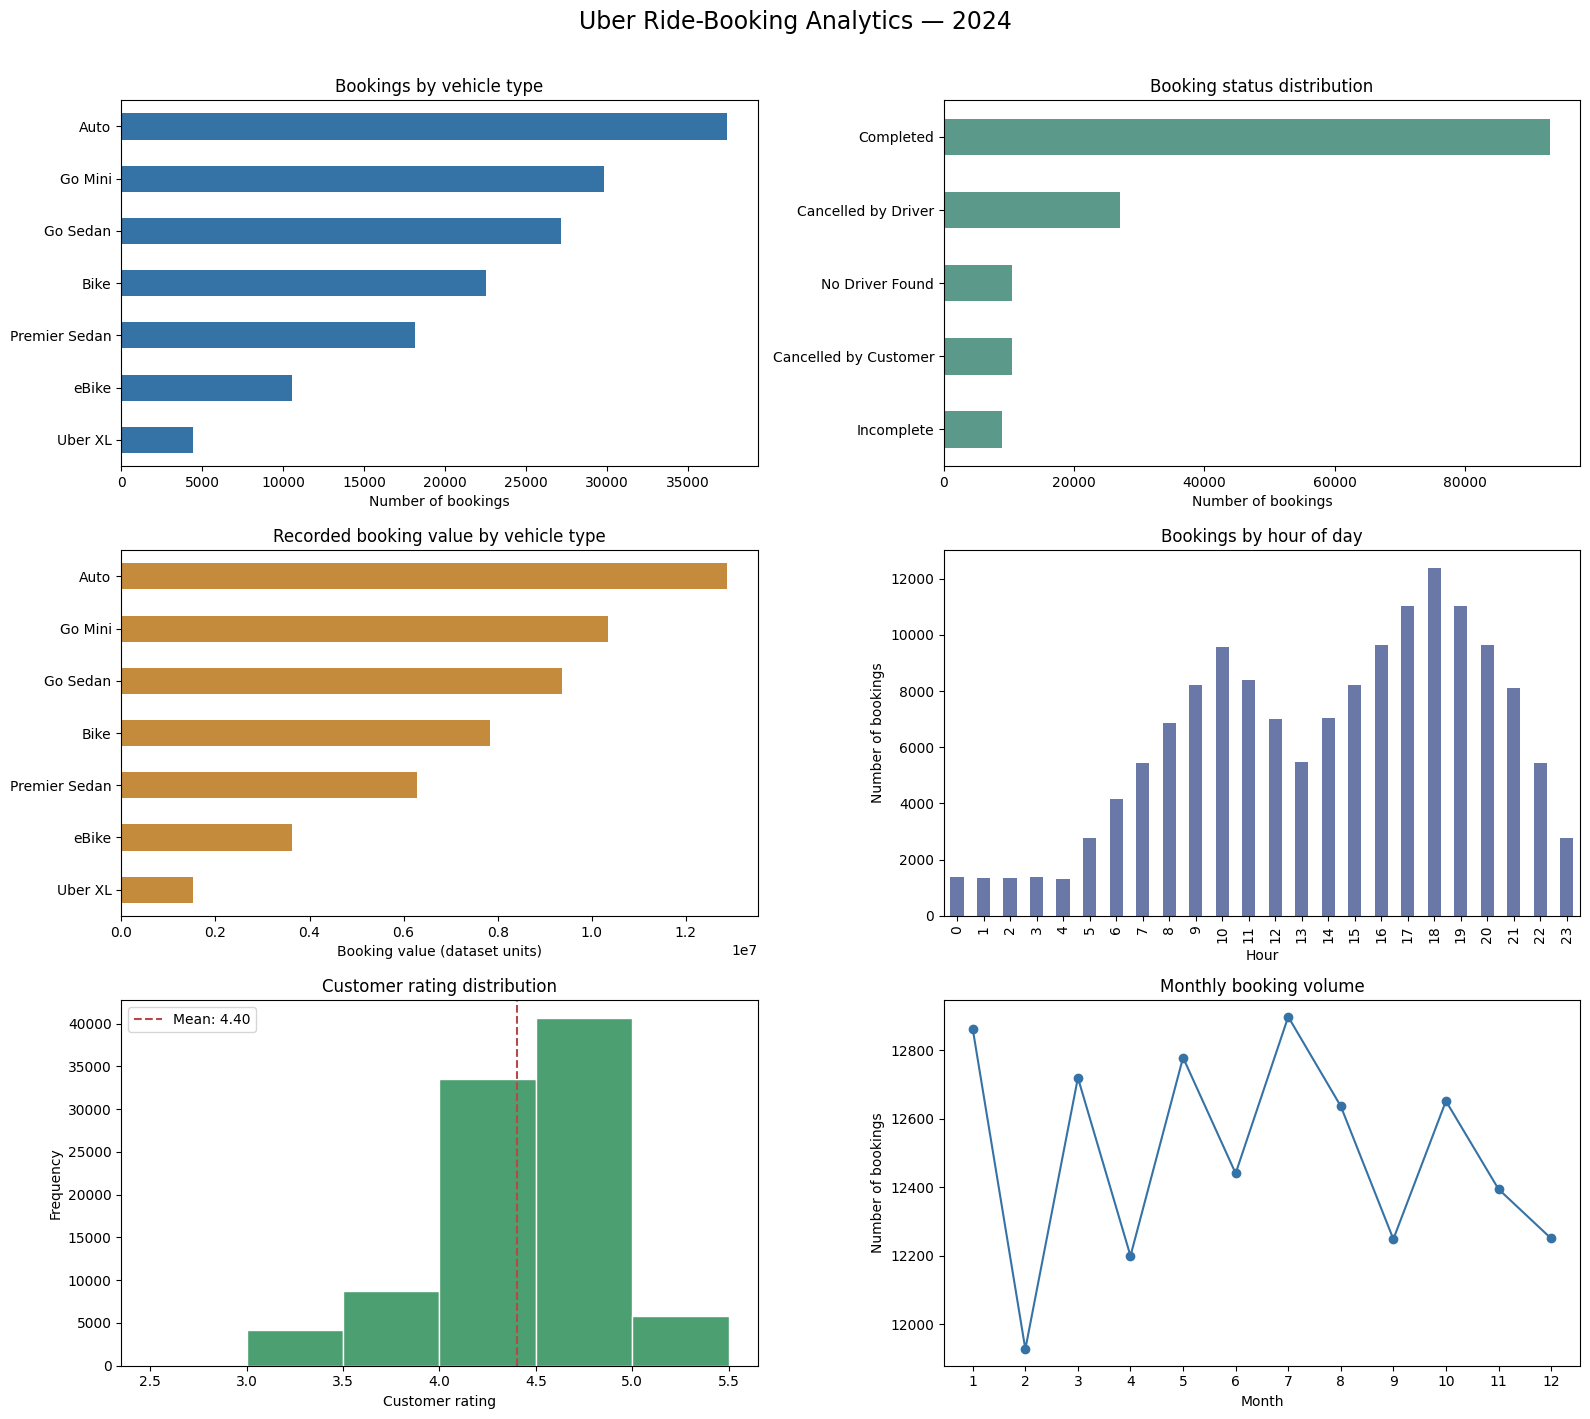

In [8]:
fig, axes = plt.subplots(3, 2, figsize=(16, 14))

# 1. Booking volume by vehicle type
vehicle_summary["bookings"].sort_values().plot(
    kind="barh", ax=axes[0, 0], color="#3572A5"
)
axes[0, 0].set_title("Bookings by vehicle type")
axes[0, 0].set_xlabel("Number of bookings")
axes[0, 0].set_ylabel("")

# 2. Booking status distribution
status_counts = df["Booking Status"].value_counts()
status_counts.sort_values().plot(
    kind="barh", ax=axes[0, 1], color="#5B9A8B"
)
axes[0, 1].set_title("Booking status distribution")
axes[0, 1].set_xlabel("Number of bookings")
axes[0, 1].set_ylabel("")

# 3. Recorded booking value by vehicle type
vehicle_summary["recorded_booking_value"].sort_values().plot(
    kind="barh", ax=axes[1, 0], color="#C58B3C"
)
axes[1, 0].set_title("Recorded booking value by vehicle type")
axes[1, 0].set_xlabel("Booking value (dataset units)")
axes[1, 0].set_ylabel("")

# 4. Booking volume by hour
df.groupby("Hour")["Booking ID"].count().sort_index().plot(
    kind="bar", ax=axes[1, 1], color="#6A78A8"
)
axes[1, 1].set_title("Bookings by hour of day")
axes[1, 1].set_xlabel("Hour")
axes[1, 1].set_ylabel("Number of bookings")

# 5. Customer rating distribution (observed values only)
customer_ratings = df["Customer Rating"].dropna()
axes[2, 0].hist(
    customer_ratings, bins=np.arange(2.5, 5.6, 0.5),
    color="#4C9F70", edgecolor="white"
)
axes[2, 0].axvline(
    customer_ratings.mean(), color="#B54848", linestyle="--",
    label=f"Mean: {customer_ratings.mean():.2f}"
)
axes[2, 0].set_title("Customer rating distribution")
axes[2, 0].set_xlabel("Customer rating")
axes[2, 0].set_ylabel("Frequency")
axes[2, 0].legend()

# 6. Booking volume by month
df.groupby("Month")["Booking ID"].count().sort_index().plot(
    kind="line", marker="o", ax=axes[2, 1], color="#3572A5"
)
axes[2, 1].set_title("Monthly booking volume")
axes[2, 1].set_xlabel("Month")
axes[2, 1].set_ylabel("Number of bookings")
axes[2, 1].set_xticks(range(1, 13))

fig.suptitle("Uber Ride-Booking Analytics — 2024", fontsize=17, y=1.01)
fig.tight_layout()
plt.show()

## 8. Multiple linear regression (OLS)

The OLS model is estimated on **completed rides only**. Observations with missing values in any model variable are excluded using listwise deletion. The dependent variable is the natural logarithm of booking value.

### Specification

\`log(Booking Value)\` is modelled as a function of ride distance, average driver arrival time, average trip time, driver rating, customer rating, a weekend indicator and a peak-hour indicator.

The model is exploratory. Coefficients describe conditional associations in this sample; they should not be interpreted as causal effects.

In [9]:
model_columns = [
    "Booking Value",
    "Ride Distance",
    "Avg VTAT",
    "Avg CTAT",
    "Driver Ratings",
    "Customer Rating",
]

df_model = df.loc[df["Booking Status"].eq("Completed")].copy()
df_model = df_model.dropna(subset=model_columns)

df_model["Hour"] = pd.to_datetime(
    df_model["Time"], format="%H:%M:%S", errors="coerce"
).dt.hour
df_model["Date"] = pd.to_datetime(df_model["Date"], errors="coerce")
df_model["Weekend"] = df_model["Date"].dt.dayofweek.isin([5, 6]).astype(int)
df_model["PeakHour"] = df_model["Hour"].isin(
    [7, 8, 9, 17, 18, 19, 20]
).astype(int)
df_model["log_Booking_Value"] = np.log(df_model["Booking Value"])

df_model = df_model.rename(
    columns={
        "Ride Distance": "Ride_Distance",
        "Avg VTAT": "Avg_VTAT",
        "Avg CTAT": "Avg_CTAT",
        "Driver Ratings": "Driver_Ratings",
        "Customer Rating": "Customer_Rating",
    }
)

formula = (
    "log_Booking_Value ~ Ride_Distance + Avg_VTAT + Avg_CTAT + "
    "Driver_Ratings + Customer_Rating + Weekend + PeakHour"
)

ols_results = smf.ols(formula=formula, data=df_model).fit()

print(f"OLS estimation sample: {int(ols_results.nobs):,} completed rides")
print(f"R-squared: {ols_results.rsquared:.4f}")
print(f"Adjusted R-squared: {ols_results.rsquared_adj:.4f}")
display(ols_results.summary())

OLS estimation sample: 93,000 completed rides
R-squared: 0.0479
Adjusted R-squared: 0.0478


<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:      log_Booking_Value   R-squared:                       0.048
Model:                            OLS   Adj. R-squared:                  0.048
Method:                 Least Squares   F-statistic:                     667.7
Date:                Tue, 24 Nov 2026   Prob (F-statistic):               0.00
Time:                        13:01:26   Log-Likelihood:            -1.0651e+05
No. Observations:               93000   AIC:                         2.130e+05
Df Residuals:                   92992   BIC:                         2.131e+05
Df Model:                           7                                         
Covariance Type:            nonrobust                                         
===================================================================================
                      coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------
Intercept           5.8457      0.037    158.657      0.000       5.773       5.918
Ride_Distance       0.0001      0.000      0.734      0.463      -0.000       0.000
Avg_VTAT            0.0011      0.001      1.680      0.093      -0.000       0.002
Avg_CTAT        -6.281e-05      0.000     -0.218      0.828      -0.001       0.001
Driver_Ratings     -0.0002      0.006     -0.026      0.979      -0.011       0.011
Customer_Rating    -0.0031      0.006     -0.542      0.588      -0.014       0.008
Weekend             0.3764      0.006     68.322      0.000       0.366       0.387
PeakHour            0.0050      0.005      0.992      0.321      -0.005       0.015
==============================================================================
Omnibus:                     2195.389   Durbin-Watson:                   2.006
Prob(Omnibus):                  0.000   Jarque-Bera (JB):             2243.189
Skew:                          -0.360   Prob(JB):                         0.00
Kurtosis:                       2.756   Cond. No.                         635.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

## 9. Interpretation and limitations

### Descriptive findings

- The dataset contains **150,000 bookings**. **93,000** are recorded as completed.
- **Auto** is the most frequently booked vehicle category, followed by **Go Mini** and **Go Sedan**.
- Driver cancellations, customer cancellations, bookings with no driver found and incomplete rides represent distinct operational outcomes and are kept separate in the classification.
- The mean booking value is calculated only over observations where booking value is recorded; it should not be interpreted as an average across all 150,000 bookings.
- Missing values are partly status-dependent. Preserving this structure avoids assigning artificial fares, distances or ratings to bookings for which those measures are not observed.

### OLS interpretation

The OLS model is estimated on completed rides. Its R-squared should be considered alongside the coefficients and the modelling assumptions. A low R-squared indicates that the selected predictors explain only a limited share of the variation in log booking value. The model is therefore best treated as an exploratory association analysis, not as a high-accuracy fare predictor.

### Limitations

- The dataset is observational; estimated relationships do not establish causality.
- Missingness is not random across all booking statuses.
- The dataset's geographic and currency context should be checked against its original Kaggle listing before making market-level comparisons.
- The specification includes a limited set of explanatory variables; pricing may also depend on factors not represented in the data.

## 10. Reproducibility

The CSV is stored in the repository's `data/` folder. The notebook resolves this path whether it is launched from the repository root or from `notebooks/`.

Install the packages listed in `requirements.txt`, open this notebook in Jupyter and run the cells from top to bottom.

---

**Author:** Alexandru Măroiu  
**Institution:** Bucharest University of Economic Studies (ASE)  
**Project scope:** Individual Python notebook developed within a broader collaborative university assignment.